# 1 · Hypothesis H3: open public holidays

**Purpose.** This notebook tests hypothesis **H3** (canvas block 2):

> Per product group, revenue is higher on public holidays (Schleswig-Holstein) on which the shop is open than on the same weekday without a holiday.

**Why it matters.** The current practice and our baseline bake "what sold on the same weekday last week" (D−7). A public holiday is a single day; the week before was an ordinary day. If holidays sell clearly more, the baseline is too low on exactly these days, and a holiday feature should help the model.

**The plan** is in [`docs/h3-holidays-plan.md`](../docs/h3-holidays-plan.md); the decisions behind it are in `DECISIONS.md` (2026-11-22). In short:

| Step | What we do |
|---|---|
| 1 | Load the prepared data, keep the **training period** only (the validation year stays untouched) |
| 2 | Load public holidays from the `holidays` package and **check** them against the sales data (K13) |
| 3 | Label every day: *open public holiday*, *special day*, or *normal day* |
| 4 | Compute the **holiday ratio** for each holiday and product group |
| 5 | Summarise: all holidays together |
| 6 | Summarise: per holiday |
| 7 | How far does the D−7 baseline miss on holidays? |
| 8 | Special days (Easter Sunday, Whit Sunday, Christmas Eve, New Year's Eve) |
| 9 | Result |

## 0. Setup

We import the libraries and our own project code:
- `bakery_holidays` (in `src/`) loads the public holidays and defines the special days.
- `invariants` (in `checks/`) holds the checks, so the notebook runs the same checks as `uv run pytest checks`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import wilcoxon

# Find the project root, whether the notebook is started from its own folder or from the root
ROOT = Path.cwd().parent if Path.cwd().name == "1_DatasetCharacteristics" else Path.cwd()
sys.path[:0] = [str(ROOT / "src"), str(ROOT / "checks")]

import bakery_holidays as hol
import bakery_prep as prep
import invariants as inv

WEEKDAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
GROUPS = {1: "Bread", 2: "Rolls", 3: "Croissants", 4: "Confectionery", 5: "Cakes", 6: "Seasonal bread"}

# Settings from the plan (docs/h3-holidays-plan.md)
WINDOW_WEEKS = 4          # compare with the same weekday 1-4 weeks before and after
MIN_COMPARISON_DAYS = 3   # a holiday needs at least this many comparison days, otherwise no ratio
THRESHOLD_RATIO = 1.10    # "supported" needs a median ratio of at least 1.10 (10 % more) ...
THRESHOLD_HIGHER = 13     # ... and higher revenue on at least 13 of the 17 holidays

## 1. Load the prepared data (training period only)

The file comes from `0_DataPreparation/01_load_join_clean.ipynb`: one row per date and product group, with weather and Kiel Week, weather-gap days removed, and a `split` column. We keep only the **training** rows (before 2017-08-01).

In [2]:
prepared = pd.read_csv(ROOT / "0_DataPreparation" / "output" / "bakery_prepared.csv", parse_dates=["Datum"])
train = prepared[prepared["split"] == "train"].copy()

# Readable helper columns: weekday name (ordered Monday to Sunday) and product group name
train["weekday"] = pd.Categorical(train["Datum"].dt.day_name(), categories=WEEKDAYS, ordered=True)
train["group"] = train["Warengruppe"].map(GROUPS)

print(f"Training data: {len(train):,} rows on {train['Datum'].nunique():,} dates, "
      f"{train['Datum'].min().date()} to {train['Datum'].max().date()}")

Training data: 7,487 rows on 1,461 dates, 2013-07-01 to 2017-07-31


## 2. Public holidays from the `holidays` package

The package [`holidays`](https://github.com/vacanza/holidays) knows the public holidays of every German state, including past changes (for example, Reformation Day was a holiday in Schleswig-Holstein once in 2017 and every year from 2018).

**Checkpoint K13.** Before we use the list, we test it against the raw sales data. It must contain 46 public holidays in the sales period. Exactly the 20 known ones must have sales, and the other 26 must be among the known closed days. If the source were wrong (a missing or shifted holiday), the notebook would stop here.

In [3]:
# The raw sales are needed for the check: they contain every open day of the whole sales period
raw_sales = prep.load_sales()

public_holidays = hol.public_holidays_sh(inv.FIRST_DATE, inv.LAST_DATE)
inv.check_public_holidays(public_holidays, raw_sales)  # K13
print(f"K13 passed: {len(public_holidays)} public holidays in the sales period")

# Which holidays was the shop open on? "open" = there are sales on that date
open_dates = set(raw_sales["Datum"])
public_holidays["shop open"] = public_holidays["Datum"].isin(open_dates)

(public_holidays
    .groupby("Feiertag", sort=False)["shop open"]
    .agg(open="sum", closed=lambda s: (~s).sum()))

K13 passed: 46 public holidays in the sales period


,open,closed
Feiertag,,
Tag der Deutschen Einheit,5,0
Erster Weihnachtstag,0,5
Zweiter Weihnachtstag,0,5
Neujahr,0,5
Karfreitag,0,5
Ostermontag,5,0
Erster Mai,1,4
Christi Himmelfahrt,5,0
Pfingstmontag,4,1


**What to notice:** the shop opens on the same holidays every year: Easter Monday, Ascension Day, Whit Monday and German Unity Day. Whit Monday 2018 is the one exception (closed), and 1 May was open only once, in 2016, when it fell on a Sunday. On Christmas, New Year and Good Friday the shop is always closed, so those days cannot tell us anything about sales.

## 3. Label every day

Each training day gets one of three labels (column `day_type`):
- **open public holiday**: a public holiday with sales. This is what H3 is about.
- **special day**: Easter Sunday, Whit Sunday, Christmas Eve, New Year's Eve. These are not public holidays, but likely unusual days. We look at them separately in step 8.
- **normal day**: everything else.

In [4]:
special = hol.special_days(inv.FIRST_DATE, inv.LAST_DATE)

# Look-up tables: date -> name of the holiday / special day
holiday_name = dict(zip(public_holidays["Datum"], public_holidays["Feiertag"]))
special_name = dict(zip(special["Datum"], special["Feiertag"]))

train["day_type"] = "normal day"
train.loc[train["Datum"].isin(holiday_name), "day_type"] = "open public holiday"
train.loc[train["Datum"].isin(special_name), "day_type"] = "special day"
train["holiday"] = train["Datum"].map(holiday_name).fillna(train["Datum"].map(special_name))

# How many dates of each type are in the training period, and on which weekdays?
day_overview = train.drop_duplicates("Datum")
pd.crosstab(day_overview["day_type"], day_overview["weekday"], margins=True, margins_name="total")

weekday,Monday,Tuesday,Wednesday,Thursday,Friday,Saturday,Sunday,total
day_type,,,,,,,,
normal day,201,210,209,200,204,206,198,1428
open public holiday,9,0,0,5,1,1,1,17
special day,0,2,2,2,0,2,8,16
total,210,212,211,207,205,209,207,1461


**What to notice:** there are **17 open public holidays** in the training period, almost all on a Monday (Easter and Whit Monday) or a Thursday (Ascension Day). Only German Unity Day moves through the week. So we cannot tell whether a holiday effect would look the same on, say, a Tuesday.

Which product groups have a row on these holidays?

In [5]:
holiday_rows = train[train["day_type"] == "open public holiday"]
holiday_rows.groupby(["Warengruppe", "group"]).size().rename("holidays with sales").to_frame()

,,holidays with sales
Warengruppe,group,
1,Bread,17
2,Rolls,17
3,Croissants,17
4,Confectionery,17
5,Cakes,17


Seasonal bread (6) never appears: its season starts in late October at the earliest, after German Unity Day. So H3 is tested for groups 1–5 only.

## 4. The holiday ratio

**Idea.** To see whether a holiday sells more, we need a fair comparison: a day that is like the holiday in every respect *except* being a holiday. Two things have a strong effect on revenue and must be the same:
- the **weekday** (a Monday sells differently from a Saturday), and
- the **season** (Easter is in spring, German Unity Day in autumn).

So we compare each holiday with the **same weekday in the 4 weeks before and the 4 weeks after** (up to 8 days), taking the **median** (the middle value, which a single unusual day cannot drag around). Other holidays, special days and Kiel Week days are left out of the comparison, because they are unusual days themselves.

**holiday ratio = revenue on the holiday ÷ median revenue on the comparison days**

A ratio of 1.00 means "same as usual", 1.25 means "25 % more", 0.90 means "10 % less".

*Note:* using the weeks *after* a holiday is fine here because we only describe the past. A forecast model could never use them (canvas block 6).

*Kiel Week:* we also exclude **Kiel Week** days from the comparison. Whit Monday is sometimes 2 to 4 weeks before Kiel Week, and Kiel Week days sell more, which would make the holiday look smaller than it is (DECISIONS.md, 2026-11-22).

In [6]:
# Days that may serve as comparison days: normal days that are not in Kiel Week
comparison_pool = train[(train["day_type"] == "normal day") & (train["KielerWoche"] == 0)]


def comparison_revenue(day, product_group):
    """Median revenue of one product group on the same weekday, 1-4 weeks before and after `day`."""
    weeks = [w for w in range(-WINDOW_WEEKS, WINDOW_WEEKS + 1) if w != 0]
    comparison_days = [day + pd.Timedelta(weeks=w) for w in weeks]

    rows = comparison_pool[(comparison_pool["Warengruppe"] == product_group)
                           & comparison_pool["Datum"].isin(comparison_days)]
    return rows["Umsatz"].median(), len(rows)


def holiday_ratios(day_rows):
    """One row per (day, product group): its revenue, the usual revenue and the ratio."""
    results = []
    for _, row in day_rows.iterrows():
        usual_revenue, n_days = comparison_revenue(row["Datum"], row["Warengruppe"])
        if n_days < MIN_COMPARISON_DAYS:
            usual_revenue = np.nan  # too few comparison days for a fair ratio
        results.append({
            "Datum": row["Datum"],
            "holiday": row["holiday"],
            "weekday": row["weekday"],
            "group": row["group"],
            "revenue": row["Umsatz"],
            "usual revenue": usual_revenue,
            "comparison days": n_days,
        })
    table = pd.DataFrame(results)
    table["ratio"] = table["revenue"] / table["usual revenue"]
    # Keep the product groups in their usual order (1 Bread ... 6 Seasonal bread)
    table["group"] = pd.Categorical(table["group"], categories=list(GROUPS.values()), ordered=True)
    return table


ratios = holiday_ratios(holiday_rows)

print(f"{len(ratios)} holiday x group combinations; comparison days per combination: "
      f"{ratios['comparison days'].min()} to {ratios['comparison days'].max()}; "
      f"without a ratio: {ratios['ratio'].isna().sum()}")
ratios.head(10).round({"revenue": 2, "usual revenue": 2, "ratio": 2})

85 holiday x group combinations; comparison days per combination: 6 to 8; without a ratio: 0


,Datum,holiday,weekday,group,revenue,usual revenue,comparison days,ratio
0,2013-10-03,Tag der Deutschen Einheit,Thursday,Bread,75.23,128.44,8,0.59
1,2014-04-21,Ostermontag,Monday,Bread,109.43,154.34,8,0.71
2,2014-05-29,Christi Himmelfahrt,Thursday,Bread,85.88,134.86,6,0.64
3,2014-06-09,Pfingstmontag,Monday,Bread,110.84,142.24,7,0.78
4,2014-10-03,Tag der Deutschen Einheit,Friday,Bread,62.59,136.32,8,0.46
5,2015-04-06,Ostermontag,Monday,Bread,60.14,132.94,8,0.45
6,2015-05-14,Christi Himmelfahrt,Thursday,Bread,53.43,116.68,8,0.46
7,2015-05-25,Pfingstmontag,Monday,Bread,93.85,131.80,7,0.71
8,2015-10-03,Tag der Deutschen Einheit,Saturday,Bread,59.61,149.74,8,0.40
9,2016-03-28,Ostermontag,Monday,Bread,78.94,115.29,8,0.68


**What to check:** every combination should have enough comparison days (at least 3, usually close to 8). The first rows are a sanity check: does "usual revenue" look like a plausible day for that group and weekday?

## 5. Result: all holidays together

For each product group:
- **median ratio**: the typical holiday effect,
- **lowest / highest**: the range across the 17 holidays,
- **holidays higher**: on how many holidays revenue was above the usual level,
- **H3 supported?**: median ratio ≥ 1.10 **and** at least 13 of 17 holidays higher (the criterion from canvas block 4),
- **Wilcoxon p** (extra, not the criterion): a test of whether the ratios lie systematically above 1. A small p (e.g. below 0.05) means "hard to explain by chance". With only 17 cases, it is a rough guide.

In [7]:
def summarise(table):
    """Median ratio, range, count of higher days and the H3 criterion, per product group."""
    rows = []
    for group_name, group_table in table.groupby("group", observed=True):
        group_ratios = group_table["ratio"].dropna()
        n_higher = int((group_ratios > 1).sum())
        median_ratio = group_ratios.median()
        # Wilcoxon signed-rank test on log(ratio): is the typical ratio above 1?
        p_value = wilcoxon(np.log(group_ratios), alternative="greater").pvalue
        rows.append({
            "group": group_name,
            "holidays": len(group_ratios),
            "median ratio": median_ratio,
            "lowest": group_ratios.min(),
            "highest": group_ratios.max(),
            "holidays higher": n_higher,
            "H3 supported?": "yes" if (median_ratio >= THRESHOLD_RATIO and n_higher >= THRESHOLD_HIGHER) else "no",
            "Wilcoxon p": p_value,
        })
    return pd.DataFrame(rows).set_index("group")


pooled = summarise(ratios)

# Show p-values readably: very small values as "< 0.001"
(pooled.round({"median ratio": 2, "lowest": 2, "highest": 2})
       .assign(**{"Wilcoxon p": pooled["Wilcoxon p"].map(lambda p: "< 0.001" if p < 0.001 else f"{p:.3f}")}))

,holidays,median ratio,lowest,highest,holidays higher,H3 supported?,Wilcoxon p
group,,,,,,,
Bread,17,0.59,0.15,1.25,1,no,1.000
Rolls,17,1.78,0.97,2.50,16,yes,< 0.001
Croissants,17,1.90,0.87,2.32,16,yes,< 0.001
Confectionery,17,1.98,1.11,3.04,17,yes,< 0.001
Cakes,17,1.33,0.90,1.79,15,yes,< 0.001


The chart shows every single holiday as a dot, so we can see how much the holidays vary. The black bar is the median of each group. The grey line at 1.0 means "same as usual"; the dashed line at 1.10 is our threshold.

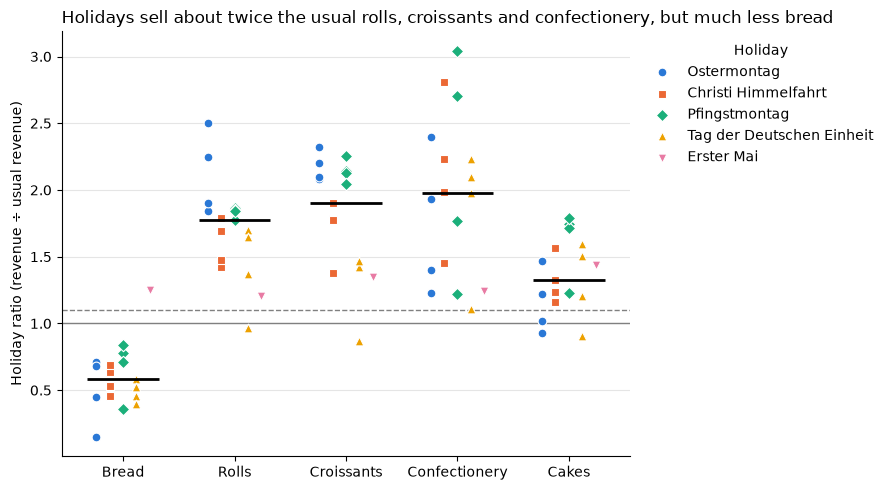

In [8]:
# One colour and one marker per holiday (fixed order, so a holiday always looks the same)
HOLIDAY_STYLE = {
    "Ostermontag":               ("#2a78d6", "o"),
    "Christi Himmelfahrt":       ("#eb6834", "s"),
    "Pfingstmontag":             ("#1baf7a", "D"),
    "Tag der Deutschen Einheit": ("#eda100", "^"),
    "Erster Mai":                ("#e87ba4", "v"),
}
group_names = [g for g in GROUPS.values() if g in set(ratios["group"])]

fig, ax = plt.subplots(figsize=(9, 5))
for x_position, group_name in enumerate(group_names):
    group_table = ratios[ratios["group"] == group_name]
    # Shift each holiday a little to the side, so the dots do not hide each other
    for shift, (holiday, (colour, marker)) in zip(np.linspace(-0.24, 0.24, len(HOLIDAY_STYLE)), HOLIDAY_STYLE.items()):
        values = group_table.loc[group_table["holiday"] == holiday, "ratio"]
        ax.scatter([x_position + shift] * len(values), values, color=colour, marker=marker, s=40,
                   edgecolor="white", linewidth=0.8, label=holiday if x_position == 0 else None, zorder=3)
    ax.hlines(group_table["ratio"].median(), x_position - 0.32, x_position + 0.32, color="black", linewidth=2, zorder=4)

ax.axhline(1.0, color="grey", linewidth=1)
ax.axhline(THRESHOLD_RATIO, color="grey", linewidth=1, linestyle="--")
ax.set_xticks(range(len(group_names)), group_names)
ax.set_ylabel("Holiday ratio (revenue ÷ usual revenue)")
ax.set_title("Holidays sell about twice the usual rolls, croissants and confectionery, but much less bread", loc="left")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e5e5e5", linewidth=0.8)
ax.set_axisbelow(True)
ax.legend(title="Holiday", frameon=False, bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

**What we see (17 open public holidays, training period):**

| Product group | Typical holiday (median ratio) | Range | Holidays higher than usual |
|---|---|---|---|
| Rolls | 1.78 (+78 %) | 0.97 – 2.50 | 16 of 17 |
| Croissants | 1.90 (+90 %) | 0.87 – 2.32 | 16 of 17 |
| Confectionery | 1.98 (+98 %) | 1.11 – 3.04 | 17 of 17 |
| Cakes | 1.33 (+33 %) | 0.90 – 1.79 | 15 of 17 |
| Bread | 0.59 (−41 %) | 0.15 – 1.25 | 1 of 17 |

- For **rolls, croissants, confectionery and cakes** both parts of the criterion are met: the typical holiday is well above +10 %, and almost every single holiday was higher. The Wilcoxon test agrees (p < 0.001).
- **Bread goes the other way**: on 16 of 17 holidays it sold *less* than on a normal day with the same weekday, typically about 40 % less.

**A possible explanation (not tested here):** this is the pattern of a **Sunday**. The prep notebook showed that bread is weakest on Sunday, while rolls, croissants and cakes are strongest at the weekend. On a day off, people buy rolls and cake for breakfast and coffee, but not bread for the week.

## 6. Result per holiday

The holidays are quite different occasions: Easter Monday and Whit Monday are typical outing days in spring, Ascension Day is a Thursday that many people take as a long weekend, and German Unity Day is in autumn. So we also look at each holiday on its own.

The table shows the **median ratio per holiday and product group**, with the number of years in the last column. With 4 years per holiday (1 May: 1), these are hints, not proof. Per holiday we give no yes/no (decision of 2026-11-22).

In [9]:
holiday_order = list(HOLIDAY_STYLE)  # same order as in the chart
per_holiday = ratios.pivot_table(index="holiday", columns="group", values="ratio", aggfunc="median", observed=True)
per_holiday = per_holiday.reindex(holiday_order)
per_holiday["years"] = ratios.drop_duplicates("Datum").groupby("holiday").size().reindex(holiday_order)
per_holiday.round(2)

group,Bread,Rolls,Croissants,Confectionery,Cakes,years
holiday,,,,,,
Ostermontag,0.57,2.07,2.15,1.66,1.12,4
Christi Himmelfahrt,0.58,1.58,1.78,2.11,1.28,4
Pfingstmontag,0.75,1.85,2.14,2.23,1.73,4
Tag der Deutschen Einheit,0.49,1.51,1.42,2.04,1.36,4
Erster Mai,1.25,1.20,1.35,1.25,1.44,1


And the single years, to see whether a holiday is consistently high or driven by one year:

In [10]:
single_years = ratios.assign(year=ratios["Datum"].dt.year)
single_years = single_years.pivot_table(index=["holiday", "year", "weekday"], columns="group",
                                        values="ratio", observed=True)
single_years.reindex(holiday_order, level=0).round(2)

group                                    Bread  Rolls  Croissants  \
holiday                   year weekday                              
Ostermontag               2014 Monday     0.71   1.84        2.20   
                          2015 Monday     0.45   2.50        2.32   
                          2016 Monday     0.68   2.25        2.08   
                          2017 Monday     0.15   1.90        2.10   
Christi Himmelfahrt       2014 Thursday   0.64   1.69        1.90   
                          2015 Thursday   0.46   1.42        1.38   
                          2016 Thursday   0.53   1.79        1.78   
                          2017 Thursday   0.69   1.48        1.78   
Pfingstmontag             2014 Monday     0.78   1.86        2.14   
                          2015 Monday     0.71   1.85        2.13   
                          2016 Monday     0.84   1.78        2.05   
                          2017 Monday     0.36   1.84        2.25   
Tag der Deutschen Einheit 2013 Thursday   0.59   1.70        1.42   
                          2014 Friday     0.46   1.65        1.42   
                          2015 Saturday   0.40   0.97        0.87   
                          2016 Monday     0.52   1.37        1.47   
Erster Mai                2016 Sunday     1.25   1.20        1.35   

group                                    Confectionery  Cakes  
holiday                   year weekday                         
Ostermontag               2014 Monday             1.23   0.93  
                          2015 Monday             1.40   1.22  
                          2016 Monday             1.93   1.47  
                          2017 Monday             2.40   1.02  
Christi Himmelfahrt       2014 Thursday           1.99   1.56  
                          2015 Thursday           2.23   1.24  
                          2016 Thursday           1.45   1.16  
                          2017 Thursday           2.81   1.33  
Pfingstmontag             2014 Monday             1.77   1.75  
                          2015 Monday             1.22   1.72  
                          2016 Monday             3.04   1.79  
                          2017 Monday             2.70   1.23  
Tag der Deutschen Einheit 2013 Thursday           1.98   1.59  
                          2014 Friday             2.10   1.21  
                          2015 Saturday           1.11   0.90  
                          2016 Monday             2.24   1.51  
Erster Mai                2016 Sunday             1.25   1.44

**What to notice:**
- The pattern is the **same on all four main holidays**: bread low (0.49–0.75), all other groups high.
- Differences between holidays: **Whit Monday** is strongest for cakes (1.73) and confectionery (2.23); **Easter Monday** is strongest for rolls (2.07) but weak for cakes (1.12, in 2014 even 0.93). One guess: the cake for Easter is bought on Easter Sunday.
- **The weekday matters.** German Unity Day 2015 fell on a **Saturday** and was hardly different from a normal Saturday (rolls 0.97, croissants 0.87, cakes 0.90). A Saturday is already a strong day, so a holiday adds little. 1 May 2016 was a Sunday: all groups were only 1.2–1.4× a normal Sunday, bread included. Both are single cases.
- The effect is stable over the years: for rolls and croissants, every holiday on a Monday, Thursday or Friday is above 1.3.

## 7. How far does the baseline miss on holidays?

The baseline predicts the revenue of the same group on the same weekday one week earlier (D−7). Here we look at the **percentage error** of that guess:

**error = (actual − baseline) ÷ actual**

A positive error means the baseline was **too low** (too little baked). We compare holidays with normal days. Days without a D−7 value (closed or not offered the week before) are left out here.

In [11]:
# Baseline: revenue of the same group 7 days earlier
week_before = train[["Datum", "Warengruppe", "Umsatz"]].copy()
week_before["Datum"] = week_before["Datum"] + pd.Timedelta(days=7)  # shift forward: D-7 revenue lands on day D
week_before = week_before.rename(columns={"Umsatz": "baseline"})

with_baseline = train.merge(week_before, on=["Datum", "Warengruppe"], how="inner")
with_baseline["error"] = (with_baseline["Umsatz"] - with_baseline["baseline"]) / with_baseline["Umsatz"]

# Only groups 1-5 (seasonal bread has no open holidays), and no special days
compared = with_baseline[(with_baseline["day_type"] != "special day") & (with_baseline["Warengruppe"] <= 5)]

baseline_check = pd.DataFrame({
    "median error, normal days":
        compared[compared["day_type"] == "normal day"].groupby("Warengruppe")["error"].median(),
    "median error, holidays":
        compared[compared["day_type"] == "open public holiday"].groupby("Warengruppe")["error"].median(),
    "median size of error, normal days":
        compared[compared["day_type"] == "normal day"].groupby("Warengruppe")["error"].apply(lambda e: e.abs().median()),
    "median size of error, holidays":
        compared[compared["day_type"] == "open public holiday"].groupby("Warengruppe")["error"].apply(lambda e: e.abs().median()),
    "holidays": compared[compared["day_type"] == "open public holiday"].groupby("Warengruppe").size(),
})
baseline_check.index = baseline_check.index.map(GROUPS)

# Show as percentages, e.g. 0.41 -> 41 %
baseline_check.style.format({c: "{:+.0%}" for c in baseline_check.columns[:2]}
                            | {c: "{:.0%}" for c in baseline_check.columns[2:4]})

,"median error, normal days","median error, holidays","median size of error, normal days","median size of error, holidays",holidays
Warengruppe,,,,,
Bread,-0%,-80%,19%,80%,17
Rolls,-0%,+41%,10%,41%,17
Croissants,-1%,+47%,16%,47%,17
Confectionery,-2%,+49%,22%,49%,17
Cakes,-1%,+26%,12%,26%,17


**What we see:**
- On **normal days** the baseline is right on average (median error close to 0 %), and its typical miss is 10–22 %, depending on the group.
- On **holidays** it misses in one direction, and by a lot: it is **too low** by 26 % (cakes) to 49 % (confectionery), and for bread it is far **too high**. An error of −80 % means the baseline predicted about 1.8 times what was actually sold.

So holidays are exactly the days on which "same weekday last week" fails. A holiday feature in the model should help on these days, *per product group*, because bread moves in the opposite direction.

*Not examined here:* one week **after** a holiday, the baseline uses the holiday as "last week" and should be too high. That matters for the model, too.

## 8. Special days (not part of H3)

Easter Sunday, Whit Sunday, Christmas Eve and New Year's Eve are not public holidays, but the shop is open and they may sell differently. We use the same holiday ratio. They are reported separately because they are not what H3 asks.

In [12]:
special_rows = train[train["day_type"] == "special day"]
special_ratios = holiday_ratios(special_rows)

special_order = ["Ostersonntag", "Pfingstsonntag", "Heiligabend", "Silvester"]
special_table = special_ratios.pivot_table(index="holiday", columns="group", values="ratio",
                                           aggfunc="median", observed=True).reindex(special_order)
special_table["years"] = special_ratios.drop_duplicates("Datum").groupby("holiday").size().reindex(special_order)
special_table.round(2)

group,Bread,Rolls,Croissants,Confectionery,Cakes,Seasonal bread,years
holiday,,,,,,,
Ostersonntag,1.29,1.44,1.41,1.15,1.13,NaN,4
Pfingstsonntag,1.18,1.10,1.20,1.39,1.06,NaN,4
Heiligabend,1.88,1.64,1.05,1.62,1.11,0.67,4
Silvester,2.41,2.32,1.67,0.58,7.33,0.39,4


**What to notice** (4 years each, so hints only):
- **New Year's Eve** is the most unusual day: cakes about **7×** the usual level, bread and rolls more than 2×. Confectionery (0.58) and seasonal bread (0.39) are lower.
- **Christmas Eve**: bread 1.88, rolls 1.64, confectionery 1.62; cakes and croissants about normal; seasonal bread lower (0.67).
- **Easter Sunday and Whit Sunday** are compared with other Sundays and are moderately higher (1.06–1.44).
- The comparison days for Christmas Eve and New Year's Eve are December days, which are already unusual (Christmas season). So these ratios are only a rough guide.

For the model, New Year's Eve in particular needs its own treatment; a single holiday feature would not capture a 7× cake day.

## 9. Result for H3

**H3 is supported for rolls, croissants, confectionery and cakes, and contradicted for bread.**

On the open public holidays (Easter Monday, Ascension Day, Whit Monday, German Unity Day), compared with a normal day with the same weekday in the same season, the shop sold typically:

| Product group | Typical holiday | H3 |
|---|---|---|
| Rolls | about 1.8× (+78 %) | supported |
| Croissants | about 1.9× (+90 %) | supported |
| Confectionery | about 2× (+98 %) | supported |
| Cakes | about 1.3× (+33 %) | supported |
| Bread | about 0.6× (−41 %) | **not supported: lower, not higher** |

**For the operations manager (draft sentence for the memo):** "On Easter Monday, Ascension Day, Whit Monday and German Unity Day, plan about twice the usual amount of rolls, croissants and confectionery, about a third more cakes, and about 40 % less bread than on a normal day with the same weekday. Last week's sales are a poor guide on these days."

**How sure are we?**
- The direction is clear: 15–17 of 17 holidays point the same way in each group.
- The size is less certain: it rests on 17 days, 4 per holiday, and the single values vary (e.g. rolls 0.97–2.50).
- Almost all holidays were on a Monday or Thursday. On the two weekend holidays (a Saturday and a Sunday) the effect was much smaller. We cannot say how a holiday on a Tuesday or Wednesday would behave.
- Revenue shows what was sold, not what customers wanted. If rolls sold out on holidays, real demand was even higher.
- The 3 holidays in the validation year were not used. They are the first test of whether a holiday feature works.

**What follows for the model:** a holiday feature is worth trying, and it must act **per product group** (bread goes the other way). New Year's Eve and Christmas Eve need their own treatment. The week after a holiday is a known weak spot of the D−7 baseline.